### CNN Classification model

Réalisé par : Abdelkader Arras


#  Classification de Gemmes avec Transfer Learning (EfficientNetB0)


Dans ce projet, j’ai développé un modèle de classification d’images visant à reconnaître automatiquement 87 types de pierres précieuses. L’architecture repose sur une approche moderne de transfer learning utilisant EfficientNetB0 comme base : un réseau convolutif pré-entraîné sur ImageNet, chargé d’extraire des caractéristiques visuelles complexes. La partie supérieure du modèle est personnalisée avec un GlobalAveragePooling2D, une couche Dense de 256 neurones, un Dropout à 50% pour limiter le surapprentissage, puis une couche de sortie softmax adaptée aux 87 classes. Dans une première phase, le modèle est entraîné avec la base congelée, puis une seconde phase de fine-tuning permet de ré-entraîner progressivement les couches supérieures d’EfficientNet afin d’améliorer la précision. L’ensemble du pipeline inclut de l’augmentation de données, une gestion du déséquilibre, et une évaluation finale sur un jeu de test indépendant.

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
tf.keras.backend.clear_session()
import numpy as np
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

###  Chargement et Répartition des Données

Dans cette section, nous chargeons les images du dataset et nous créons trois sous-ensembles essentiels pour l’entraînement du modèle :

- **Train set (80%)** : utilisé pour apprendre les paramètres du modèle.
- **Validation set (20%)** : extrait automatiquement depuis le dossier *train* grâce à `validation_split=0.2`.
  Il permet d’évaluer la performance pendant l’entraînement et de détecter l’overfitting.
- **Test set** : contient des images totalement inédites pour mesurer la performance finale du modèle.

Nous utilisons `image_dataset_from_directory` pour organiser automatiquement les images en batches, les redimensionner à **224×224**, et mélanger les données du train (`shuffle=True`) pour améliorer l’apprentissage. Le paramètre `seed=123` garantit une séparation reproductible entre train et validation.
ona fait répartit notre dataset a trois parties


In [34]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    "gemstones_dataset/train",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(224, 224), #la taille d'entrée standard pour le modèle EfficientNetB0.
    batch_size=32,
    shuffle=True           #Les données d'entraînement sont mélangées pour éviter que le modèle n'apprenne l'ordre des images.
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    "gemstones_dataset/train",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224), #la taille d'entrée standard pour le modèle EfficientNetB0.
    batch_size=32
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    "gemstones_dataset/test",
    image_size=(224, 224), #la taille d'entrée standard pour le modèle EfficientNetB0.
    batch_size=32
)

Found 2856 files belonging to 87 classes.
Using 2285 files for training.
Found 2856 files belonging to 87 classes.
Using 571 files for validation.
Found 363 files belonging to 87 classes.


###  Visualisation d’un Échantillon d’Images du Dataset
Cette cellule permet d’afficher un aperçu des images présentes dans le *train set*.



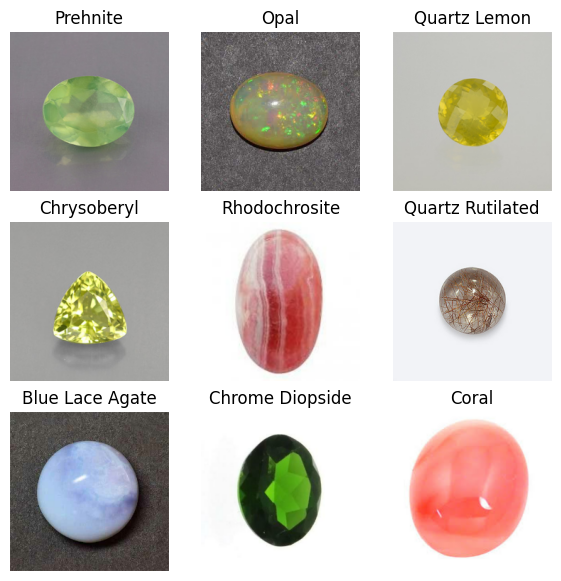

In [35]:
class_names=train_dataset.class_names
plt.figure(figsize=(7,7))
for image,labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

### Visualisation d'un Échantillon d'Images du Dataset

L'examen visuel d'un échantillon d'images du training set révèle une diversité significative qui pose des défis pour la classification. Les gemmes sont présentées avec des arrière-plans variés (blanc, noir, gris, ou coloré), obligeant le modèle à se concentrer sur la gemme elle-même plutôt que sur le contexte. De plus, on observe une forte diversité intra-classe, où des gemmes appartenant à la même catégorie présentent des variations considérables. Ces variations incluent des formes distinctes (ovale, poire, rond), des tailles variables, des coupes et facettes différentes, ainsi que des fluctuations de couleur, de transparence et de conditions d'éclairage.

Cette hétérogénéité est un facteur clé: elle rend la tâche plus difficile pour le modèle, mais elle est essentielle pour l'entraîner à apprendre les caractéristiques intrinsèques et invariantes de chaque type de pierre (sa composition, ses inclusions, son spectre de couleur), garantissant ainsi une meilleure généralisation sur des données réelles et non vues.

###  Vérification des noms et nombre de classes

In [37]:

directory = 'gemstones_dataset/train'
#printing all the gemstone categories present in our dataset
Name=[]
train_dir=sorted(os.listdir(directory))

for file in train_dir:
    Name+=[file]
print("The gemstones in the dataset are \n")
print(Name)
print("\n The count of the gemstones categories: ",len(Name))

The gemstones in the dataset are 

['Alexandrite', 'Almandine', 'Amazonite', 'Amber', 'Amethyst', 'Ametrine', 'Andalusite', 'Andradite', 'Aquamarine', 'Aventurine Green', 'Aventurine Yellow', 'Benitoite', 'Beryl Golden', 'Bixbite', 'Bloodstone', 'Blue Lace Agate', 'Carnelian', 'Cats Eye', 'Chalcedony', 'Chalcedony Blue', 'Chrome Diopside', 'Chrysoberyl', 'Chrysocolla', 'Chrysoprase', 'Citrine', 'Coral', 'Danburite', 'Diamond', 'Diaspore', 'Dumortierite', 'Emerald', 'Fluorite', 'Garnet Red', 'Goshenite', 'Grossular', 'Hessonite', 'Hiddenite', 'Iolite', 'Jade', 'Jasper', 'Kunzite', 'Kyanite', 'Labradorite', 'Lapis Lazuli', 'Larimar', 'Malachite', 'Moonstone', 'Morganite', 'Onyx Black', 'Onyx Green', 'Onyx Red', 'Opal', 'Pearl', 'Peridot', 'Prehnite', 'Pyrite', 'Pyrope', 'Quartz Beer', 'Quartz Lemon', 'Quartz Rose', 'Quartz Rutilated', 'Quartz Smoky', 'Rhodochrosite', 'Rhodolite', 'Rhodonite', 'Ruby', 'Sapphire Blue', 'Sapphire Pink', 'Sapphire Purple', 'Sapphire Yellow', 'Scapolite', 'Se

### Nombre d'images pas classe



In [38]:

class_counts = {}
for class_name in class_names:
    class_path = os.path.join("gemstones_dataset/train", class_name)
    count = len(os.listdir(class_path))
    class_counts[class_name] = count

sorted_counts = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)

print(" CLASS DISTRIBUTION ")
for gem, count in sorted_counts:
    print(f"{gem:20s}: {count:4d} images")

max_count = max(class_counts.values())
min_count = min(class_counts.values())
imbalance_ratio = max_count / min_count

print(f"Most images: {max_count}")
print(f"Least images: {min_count}")

 CLASS DISTRIBUTION 
Aventurine Green    :   45 images
Pyrite              :   43 images
Tigers Eye          :   43 images
Citrine             :   40 images
Labradorite         :   40 images
Peridot             :   39 images
Quartz Rutilated    :   38 images
Tourmaline          :   38 images
Blue Lace Agate     :   37 images
Prehnite            :   37 images
Aquamarine          :   36 images
Beryl Golden        :   36 images
Bixbite             :   36 images
Chrysocolla         :   36 images
Emerald             :   36 images
Garnet Red          :   36 images
Jasper              :   36 images
Moonstone           :   36 images
Opal                :   36 images
Rhodolite           :   36 images
Tanzanite           :   36 images
Amethyst            :   35 images
Ametrine            :   35 images
Bloodstone          :   35 images
Quartz Beer         :   35 images
Quartz Rose         :   35 images
Ruby                :   35 images
Sodalite            :   35 images
Spodumene           :   35 

Malgré un nombre de 87 classes à identifier, le volume de données par classe est excessivement limité, se situant généralement entre 27 et 45 images. Ce manque de diversité et de quantité (faible data volume) est largement insuffisant pour entraîner de manière optimale un modèle de deep learning comme EfficientNetB0, même en utilisant le Transfer Learning. Le modèle risque fortement de surapprendre les rares exemples disponibles (overfitting) et d'échouer à généraliser correctement sur de nouvelles images.

### La Solution : L'Augmentation de Données (Data Augmentation)

In [39]:
#  Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomTranslation(0.1, 0.1)
])

`RandomFlip` :	Augmente la quantité et enseigne l'invariance spatiale (la gemme est la même si elle est retournée).

`RandomRotation` :	Simule différentes orientations de prise de vue.

`RandomZoom` : 	Simule différentes distances focales ou tailles d'objets.

`RandomContrast` :	Simule les variations d'éclairage, un facteur crucial pour les gemmes.

`RandomTranslation` :	Simule de légers décalages, forçant le modèle à ne pas se fier à la position exacte dans l'image.

###  Construction du modèle EfficientNetB0

Dans cette section, nous définissons l’architecture du modèle utilisé pour la classification des 87 classes de pierres précieuses. Nous commençons par créer une entrée d’images puis appliquons le pré-traitement spécifique à EfficientNet ainsi qu’une étape d’augmentation de données pour améliorer la généralisation.
Le modèle EfficientNetB0 pré-entraîné sur ImageNet est ensuite chargé sans sa tête de classification (`include_top=False`) et gelé (`trainable=False`) pour effectuer une phase de feature extraction. Nous ajoutons ensuite une couche de global average pooling, une couche dense de 256 neurones avec activation ReLU, un Dropout à 50% pour réduire l’overfitting, puis une couche finale `Dense` avec `softmax` correspondant aux 87 classes.
Ce modèle constitue la base sur laquelle nous effectuerons l’entraînement initial avant le fine-tuning.


In [40]:

def create_gemstone_model(num_classes=87, img_size=224):
    inputs = layers.Input(shape=(img_size, img_size, 3))
    x = preprocess_input(inputs)
    x = data_augmentation(x)
    base_model = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(img_size, img_size, 3),
        pooling=None
    )

    base_model.trainable = False

    x = base_model(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(512, activation='relu',
                     kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)

    x = layers.Dropout(0.6)(x)

    x = layers.Dense(256, activation='relu')(x)

    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs)



### Création du modèle

Ce bloc de code crucial initialise le modèle de classification en utilisant l'approche de l'Extraction de Caractéristiques (Feature Extraction). La fonction create_gemstone_model construit une architecture qui utilise EfficientNetB0, un réseau de neurones convolutif pré-entraîné sur le vaste ensemble de données ImageNet. Le modèle de base est figé (base_model.trainable = False), ce qui signifie que ses millions de poids resteront inchangés. Seules les couches de la tête de classification ajoutées (couches Dense) apprendront les caractéristiques spécifiques des 87 classes de gemmes. Pour la compilation, l'optimiseur Adam est choisi avec un taux d'apprentissage standard de $0.001$, ce qui est idéal pour entraîner la tête du classifieur. La fonction de perte est la sparse_categorical_crossentropy, appropriée pour la classification multiclasse avec des étiquettes entières.

In [41]:

model = create_gemstone_model(num_classes=87, img_size=224)

In [42]:
 #parametrs of the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 87)             │        22,359 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,859,130 (18.54 MB)

 Trainable params: 809,559 (3.09 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

### Training

Cette configuration représente une méthode d'entraînement avancée de type Feature Extraction où seul le classifieur est ajusté. Elle est optimisée par l'intégration de trois callbacks essentiels : l'EarlyStopping (patience=7), qui surveille la val_loss pour stopper l'apprentissage dès que le modèle commence à surapprendre, garantissant que seuls les meilleurs poids sont conservés (restore_best_weights=True) ; le ModelCheckpoint, qui sauvegarde de manière persistante l'état du modèle ayant la plus basse val_loss sur le disque ; et le ReduceLROnPlateau, qui ajuste dynamiquement le taux d'apprentissage (réduction par un facteur de $0.5$ après patience=3 sur la val_loss) pour affiner la convergence. L'entraînement est lancé pour un maximum de 30 époques, mais il sera interrompu automatiquement par l'EarlyStopping, ce qui permet d'atteindre le pic de performance sans gaspiller de ressources ni risquer une dégradation due au surapprentissage.

In [43]:
early_stopping = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_gemstone_model.keras', monitor='val_loss', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7)
callbacks_list = [early_stopping, checkpoint, reduce_lr]

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=callbacks_list
)

Epoch 1/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 149s 2s/step - accuracy: 0.1120 - loss: 4.6474 - val_accuracy: 0.2680 - val_loss: 3.6082 - learning_rate: 0.0010
Epoch 2/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.3370 - loss: 3.1563 - val_accuracy: 0.4816 - val_loss: 2.5286 - learning_rate: 0.0010
Epoch 3/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.4792 - loss: 2.4444 - val_accuracy: 0.5412 - val_loss: 2.1601 - learning_rate: 0.0010
Epoch 4/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.5611 - loss: 2.1080 - val_accuracy: 0.5727 - val_loss: 1.9823 - learning_rate: 0.0010
Epoch 5/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.6088 - loss: 1.8917 - val_accuracy: 0.6007 - val_loss: 1.8770 - learning_rate: 0.0010
Epoch 6/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.6341 - loss: 1.7886 - val_accuracy: 0.6217 - val_loss: 1.8517 - learning_rate: 0.0010
Epoch 7/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.6394 - loss: 1.6972 - val_accura

KeyboardInterrupt: 

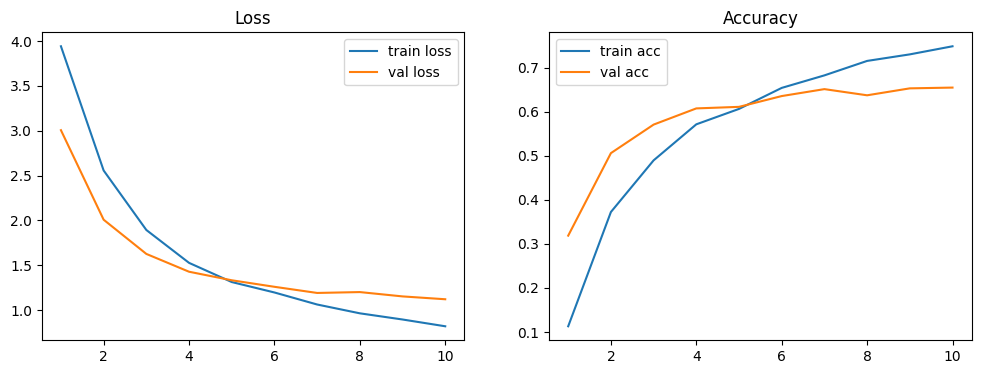

In [45]:
def plot_history(history):
    h = history.history
    epochs = range(1, len(h['loss'])+1)
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(epochs, h['loss'], label='train loss')
    plt.plot(epochs, h['val_loss'], label='val loss')
    plt.legend()
    plt.title('Loss')
    plt.subplot(1,2,2)
    plt.plot(epochs, h['accuracy'], label='train acc')
    plt.plot(epochs, h['val_accuracy'], label='val acc')
    plt.legend()
    plt.title('Accuracy')
    plt.show()

plot_history(history)


In [46]:
best_model = tf.keras.models.load_model('best_gemstone_model.keras')
best_model.evaluate(test_dataset, verbose=2)

12/12 - 29s - 2s/step - accuracy: 0.7245 - loss: 1.3732


[1.3732199668884277, 0.7245178818702698]